# Light limit (probably in the first 24 hours)


See if the extra `solar radiation` from CaSR increases diatom growth rates.

## Set up

### paths

In [4]:
import xarray as xr

path_hrdps='/ocean/jqiu/results/Flux/flux_01mar23_hrdps2.5/SalishSea_1h_20230301_20230301_chem_T.nc'
path_casr='/ocean/jqiu/results/Flux/flux_01mar23_CaSR/SalishSea_1h_20230301_20230301_chem_T.nc'

ds_hrdps=xr.open_dataset(path_hrdps)
ds_casr=xr.open_dataset(path_casr)

print(ds_hrdps)

<xarray.Dataset> Size: 7GB
Dimensions:                     (y: 898, x: 398, nvertex: 4, deptht: 40,
                                 axis_nbounds: 2, time_counter: 24)
Coordinates:
    nav_lat                     (y, x) float32 1MB ...
    nav_lon                     (y, x) float32 1MB ...
  * deptht                      (deptht) float32 160B 0.5 1.5 ... 414.5 441.5
    time_centered               (time_counter) datetime64[ns] 192B ...
  * time_counter                (time_counter) datetime64[ns] 192B 2023-03-01...
Dimensions without coordinates: y, x, nvertex, axis_nbounds
Data variables:
    bounds_nav_lon              (y, x, nvertex) float32 6MB ...
    bounds_nav_lat              (y, x, nvertex) float32 6MB ...
    area                        (y, x) float32 1MB ...
    deptht_bounds               (deptht, axis_nbounds) float32 320B ...
    time_centered_bounds        (time_counter, axis_nbounds) datetime64[ns] 384B ...
    time_counter_bounds         (time_counter, axis_nbounds) da

### Diatom limit function

In [10]:
# Calculate the Light Limitation curve for Diatoms
# Values from Code
# PE_a_flag = 0.38 # 1/(W/m2)
# PE_Iopt_flag = 20 # W/kg
PE_a_diat = 0.045 # Use this for diatom
PE_Iopt_diat = 75 # Use this for diatom
rate_R_diat = 1 #1.8e-5

# Calculation following above
PE_alpha_diat = PE_a_diat * rate_R_diat
PE_beta_diat = PE_alpha_diat / (np.exp(PE_Iopt_diat * PE_a_diat) - 1)

PE_b_diat = PE_beta_diat / rate_R_diat

PE_f_diat = ((PE_alpha_diat + PE_beta_diat) / PE_alpha_diat
* ((PE_alpha_diat + PE_beta_diat)/PE_beta_diat)**(PE_beta_diat/PE_alpha_diat) )

def light_limitation(light):
    growth = ((1 - np.exp(-light * PE_a_diat) ) * 
                       (np.exp(-light * PE_b_diat )) * PE_f_diat)
    return growth

### Regions

In [8]:

REGION = "Puget Sound"
N_LEVELS = 20

# Grid Regions
REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

MASK_FILE = "/ocean/jqiu/Grid/mesh_mask202108.nc"
AREA_FILE = "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331_biol_T.nc"


ds_grid=xr.open_dataset(MASK_FILE)
tmask=ds_grid['tmask'] # String flag_meanings "land, water"; String flag_values "0, 1", (t, z, y, x)
e3t=ds_grid['e3t_1d'] # "Grid Spacing on T-grid in w Direction", (t, z)
depth=ds_grid['gdept_1d'] # "Depth of T-grid Points", String units "m", (t, z)

ds_area=xr.open_dataset(AREA_FILE)
area=ds_area['area'] # 

## Visualize

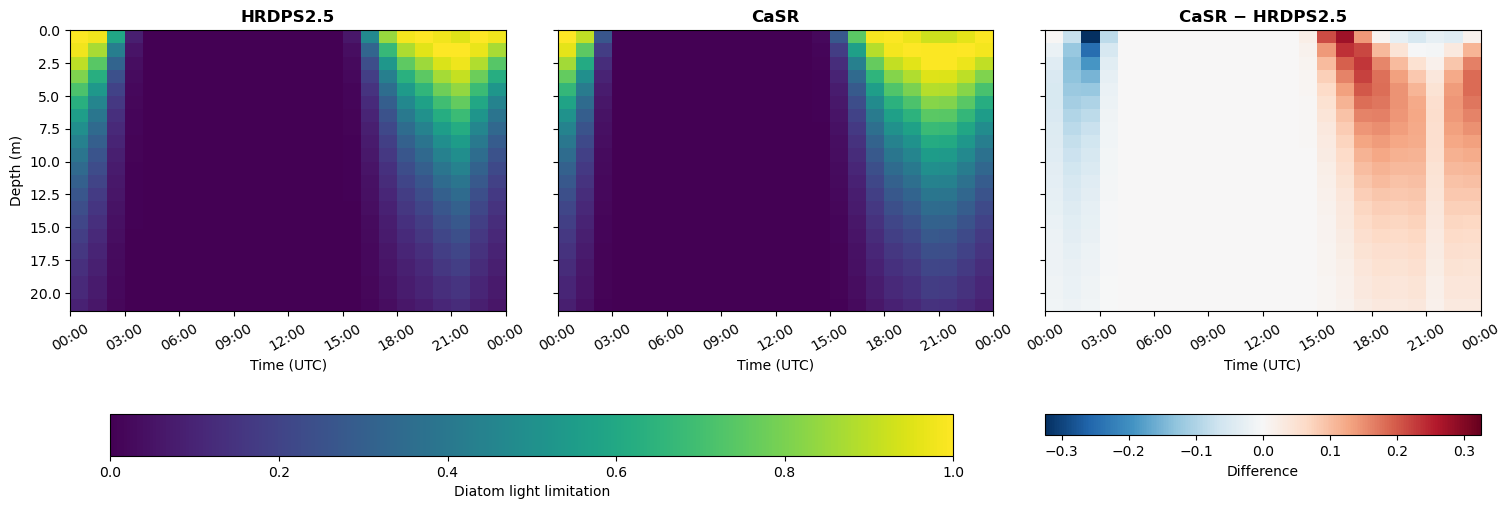

In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm


# Puget Sound area and mask


y0, y1, x0, x1 = REGIONS[REGION]

region_area = area.isel(
    y=slice(y0, y1),
    x=slice(x0, x1)
).squeeze(drop=True)

mask = tmask.isel(
    t=0,
    z=slice(0, N_LEVELS),
    y=slice(y0, y1),
    x=slice(x0, x1)
).rename({"z": "deptht"})

weights = region_area.where(mask == 1, 0)


# PAR mean


results = {}

for exp, ds in [
    ("HRDPS2.5", ds_hrdps),
    ("CaSR", ds_casr)
]:

    par = ds["PAR"].isel(
        deptht=slice(0, N_LEVELS),
        y=slice(y0, y1),
        x=slice(x0, x1)
    )

    w = weights.assign_coords(
        deptht=par.deptht,
        y=par.y,
        x=par.x
    )

    # Remove land and invalid negative PAR
    par = par.where((w > 0) & (par >= 0))

    # Area-weighted horizontal mean PAR
    par_mean = par.weighted(w).mean(dim=("y", "x"))

    # Calculate light limitation from mean PAR
    results[exp] = light_limitation(par_mean).load()


# Difference


ll_hrdps, ll_casr = xr.align(
    results["HRDPS2.5"],
    results["CaSR"],
    join="inner"
)

ll_diff = ll_casr - ll_hrdps

diff_max = max(float(abs(ll_diff).max()), 1e-12)


# Visualization


fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for i, (da, title) in enumerate(zip(
    [ll_hrdps, ll_casr, ll_diff],
    ["HRDPS2.5", "CaSR", "CaSR − HRDPS2.5"]
)):

    ax = axes[i]

    mesh = ax.pcolormesh(
        da.time_counter.values,
        da.deptht.values,
        da.transpose("deptht", "time_counter").values,
        shading="auto",
        cmap="viridis" if i < 2 else "RdBu_r",
        vmin=0 if i < 2 else None,
        vmax=1 if i < 2 else None,
        norm=None if i < 2 else TwoSlopeNorm(
            vmin=-diff_max,
            vcenter=0,
            vmax=diff_max
        )
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylim(da.deptht.max().item(), 0)

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M")
    )

    ax.tick_params(axis="x", rotation=30)

    if i < 2:
        abs_mesh = mesh
    else:
        diff_mesh = mesh

axes[0].set_ylabel("Depth (m)")

fig.colorbar(
    abs_mesh,
    ax=axes[:2],
    orientation="horizontal",
    label="Diatom light limitation",
    pad=0.12
)

fig.colorbar(
    diff_mesh,
    ax=axes[2],
    orientation="horizontal",
    label="Difference",
    pad=0.12
)


plt.show()